In [ ]:
%pip install -q landingai pillow matplotlib gTTS

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
dm-tree 0.1.10 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
google-adk 2.7.1 requires tenacity<10,>=9, but you have tenacity 8.5.0 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
jaxlib 0.11.1 requires numpy>=2.0, but you have numpy 1.26.4 which is i

In [ ]:
%pip install landingai

In [ ]:
import io
import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)

# Test Pillow's JPEG encoder independently of LandingAI
buffer = io.BytesIO()
test_image = Image.new("RGB", (10, 10), color="red")
test_image.save(buffer, format="JPEG")

print("JPEG encoding successful:", len(buffer.getvalue()), "bytes")

Pillow version: 11.3.0


TypeError: function takes at most 16 arguments (17 given)

In [9]:

from google.colab import userdata
from landingai.predict import Predictor

API_KEY = userdata.get("LANDINGAI_API_KEY")

ENDPOINT_ID = "572546fb-1c24-4496-b46c-406b5ef05d48"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized.")


LandingAI predictor initialized.


In [10]:

from google.colab import files
from PIL import Image
import io
import numpy as np

uploaded = files.upload()
filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as im:
    image = im.convert("RGB").copy()

image_array = np.array(image)

print("Image size:", image.size)
print("Image array shape:", image_array.shape)


Saving images-12.jpeg to images-12 (3).jpeg
Image size: (540, 360)
Image array shape: (360, 540, 3)


In [11]:
%pip install -q "Pillow==10.4.0"

In [12]:

predictions = predictor.predict(image_array)

print("Prediction count:", len(predictions))

for i, prediction in enumerate(predictions, start=1):
    print(f"\nPrediction {i}:")
    print(prediction)


Prediction count: 1

Prediction 1:
score=0.24769553542137146 label_name='Medicine' label_index=1 id='e8d33dc4-b547-4b3b-a137-fea6c2695634' bboxes=(329, 183, 413, 282)


Medicine Cognitive Assistant
Upload an image of a medicine bottle.


Saving images-12.jpeg to images-12 (4).jpeg


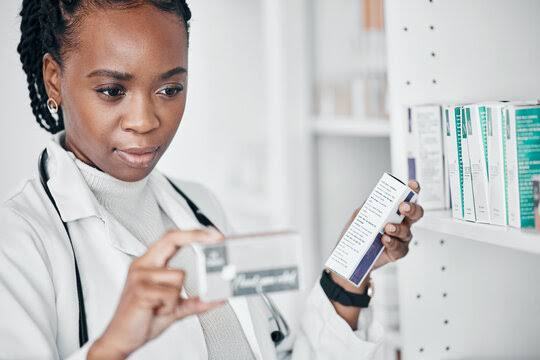


Raw model predictions:
[ObjectDetectionPrediction(score=0.24769553542137146, label_name='Medicine', label_index=1, id='eb02b545-e2fd-41f1-a2f0-a75b63531b57', bboxes=(329, 183, 413, 282))]
Predicted label: Medicine
Predicted class index: 1
Confidence: 0.24769553542137146
💊 MEDICINE DETECTED!


### Assistant response: **Medicine detected!**

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

from google.colab import files
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import numpy as np
import io

def medicine_assistant():

    print("Medicine Cognitive Assistant")
    print("Upload an image of a medicine bottle.")

    # 1. Upload image
    uploaded = files.upload()

    if not uploaded:
        print("No image uploaded.")
        return

    filename = next(iter(uploaded))

    with Image.open(io.BytesIO(uploaded[filename])) as img:
        image = img.convert("RGB").copy()

    display(image)

    # 2. Run the connected LandingAI model
    predictions = predictor.predict(np.array(image))

    print("\nRaw model predictions:")
    print(predictions)

    if not predictions:
        print("No medicine detected.")
        return

    # 3. Read the prediction
    prediction = predictions[0]

    predicted_label = getattr(prediction, "label_name", None)
    predicted_index = getattr(prediction, "label_index", None)
    confidence = getattr(prediction, "score", None)

    print("Predicted label:", predicted_label)
    print("Predicted class index:", predicted_index)
    print("Confidence:", confidence)

    # 4. Interpret the model prediction
    if predicted_label == "Medicine":
        result = "Medicine detected!"
        print("💊 MEDICINE DETECTED!")
    else:
        result = "No medicine detected."
        print("No medicine detected.")

    display(Markdown(f"### Assistant response: **{result}**"))

    # 5. Generate audio response
    speech = gTTS(text=result, lang="en")
    speech.save("medicine_response.mp3")

    display(Audio("medicine_response.mp3", autoplay=False))
    files.download("medicine_response.mp3")


medicine_assistant()

In [ ]:
# Q2: Emotion-Aware Cognitive Assistant

from google.colab import userdata
from landingai.predict import Predictor

API_KEY = userdata.get("LANDINGAI_API_KEY")

EMOTION_ENDPOINT_ID = "83b05ec6-b11d-4dcd-ab47-c141e22bad28"

emotion_predictor = Predictor(
    endpoint_id=EMOTION_ENDPOINT_ID,
    api_key=API_KEY
)

print("Emotion model predictor initialized successfully.")

Emotion model predictor initialized successfully.


Saving IMG_5060.JPG to IMG_5060 (1).JPG


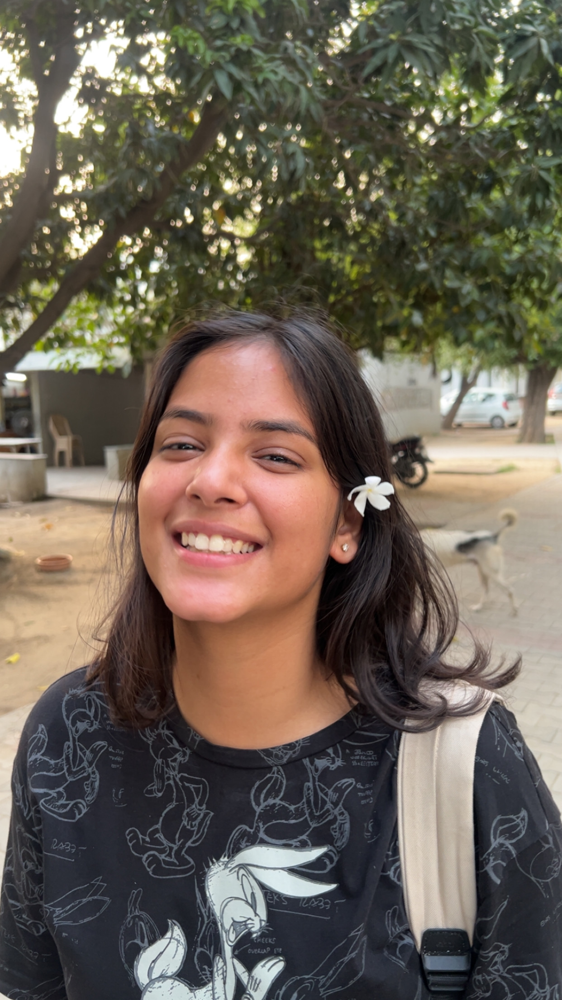

Image size: (1242, 2208)


In [16]:
from google.colab import files
from PIL import Image
from IPython.display import display
import io
import numpy as np

uploaded = files.upload()

filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as img:
    test_image = img.convert("RGB").copy()

display(test_image)

print("Image size:", test_image.size)

In [17]:
# Q2: Predict the emotion

predictions = emotion_predictor.predict(np.array(test_image))

print("Raw model predictions:")
print(predictions)

if not predictions:
    print("No emotion detected.")
else:
    prediction = predictions[0]

    predicted_emotion = getattr(prediction, "label_name", None)
    confidence = getattr(prediction, "score", None)

    print("\nPredicted emotion:", predicted_emotion)
    print("Confidence:", confidence)

Raw model predictions:
[ClassificationPrediction(score=0.25970035791397095, label_name='Happy', label_index=4)]

Predicted emotion: Happy
Confidence: 0.25970035791397095


😊 Emotion-Aware Cognitive Assistant
Upload a facial expression image.


Saving IMG_5060.JPG to IMG_5060 (3).JPG


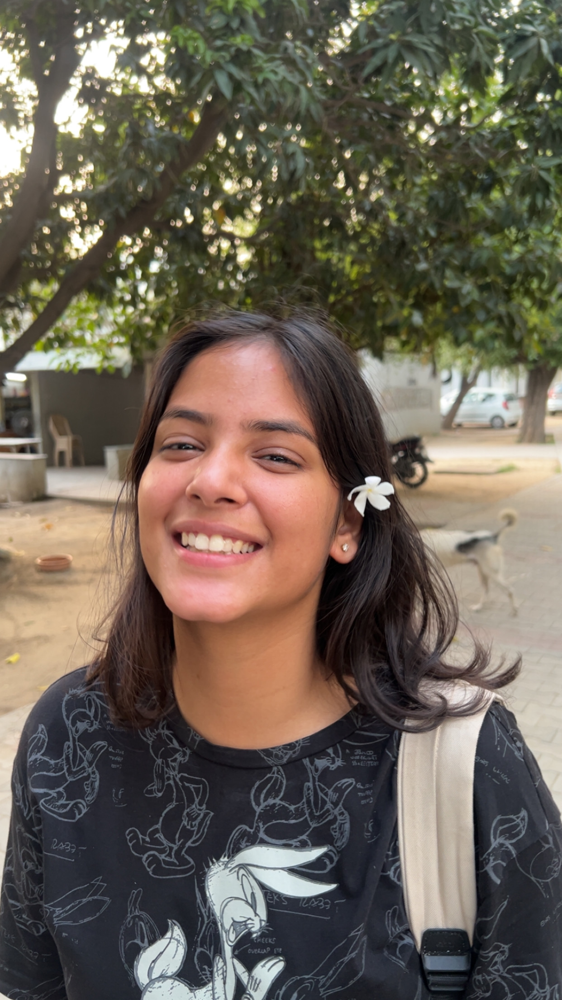


Detected Emotion: Happy
Confidence: 0.25970035791397095

🤖 Cognitive Assistant:
You seem happy! Keep smiling and have a wonderful day!


### Detected Emotion: **Happy**
**Confidence:** 25.97%

### 🤖 Assistant Response
You seem happy! Keep smiling and have a wonderful day!


Voice response generated successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# Q2: Emotion-Aware Cognitive Assistant

from google.colab import files
from PIL import Image
from IPython.display import display, Markdown, Audio
from gtts import gTTS
import io
import numpy as np

def emotion_cognitive_assistant():

    print("😊 Emotion-Aware Cognitive Assistant")
    print("Upload a facial expression image.")

    uploaded = files.upload()

    if not uploaded:
        print("No image uploaded.")
        return

    filename = next(iter(uploaded))

    with Image.open(io.BytesIO(uploaded[filename])) as img:
        image = img.convert("RGB").copy()

    display(image)

    # Predict emotion
    predictions = emotion_predictor.predict(np.array(image))

    if not predictions:
        result = "I could not detect an emotion."
        print(result)
    else:
        prediction = predictions[0]

        emotion = getattr(prediction, "label_name", None)
        confidence = getattr(prediction, "score", None)

        print("\nDetected Emotion:", emotion)
        print("Confidence:", confidence)

        # Cognitive response based on detected emotion
        responses = {
            "Happy": "You seem happy! Keep smiling and have a wonderful day!",
            "Sad": "You seem a little sad. I hope things get better soon.",
            "Angry": "You seem angry. Take a deep breath and try to relax.",
            "Surprised": "You seem surprised! Something unexpected must have happened.",
            "Neutral": "You seem calm and neutral. Have a great day!"
        }

        result = responses.get(
            emotion,
            "I detected your emotion, but I do not have a response for it."
        )

        print("\n🤖 Cognitive Assistant:")
        print(result)

        display(Markdown(
            f"### Detected Emotion: **{emotion}**\n"
            f"**Confidence:** {confidence:.2%}\n\n"
            f"### 🤖 Assistant Response\n"
            f"{result}"
        ))

    # Convert response to speech
    speech = gTTS(text=result, lang="en")
    speech.save("emotion_response.mp3")

    display(Audio("emotion_response.mp3", autoplay=False))

    print("\nVoice response generated successfully.")
    files.download("emotion_response.mp3")


emotion_cognitive_assistant()